# Public transport routing between German cities
Three ways to get transit travel times from **Berlin Hbf** to other German cities:

| Method | Cost | Coverage | Good for |
|---|---|---|---|
| **1. openrouteservice (HeiGIT)** – driving + Public Transit Router | Free key (quota) | Germany (GTFS.de), weekly refresh | Open data, research, self-hosting |
| **2. Google Routes API** – `TRANSIT` | 10,000 free/month, then $5 per 1,000 | Worldwide | Production apps, fares, polylines |
| **3. Transitous (MOTIS)** | Free | Germany + Europe | **Non-commercial open-source projects only**; >720 `/plan` calls/day needs coordination |

Run the **Setup** cell first; every method section is independent after that.

## Setup

In [ ]:
import requests
import time
import pandas as pd
from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo

ORS_API_KEY = '<YOUR_API_KEY>'        # https://account.heigit.org/signup
GOOGLE_API_KEY = '<YOUR_API_KEY>'     # Routes API enabled
CONTACT = '<YOUR_EMAIL>'              # Transitous asks for a contact in User-Agent

berlin = (52.5251, 13.3694)   # Berlin Hbf  (lat, lon)

destination_cities = {
    'Hamburg':   (53.5528, 10.0067),   # Hamburg Hbf
    'Munich':    (48.1402, 11.5600),   # München Hbf
    'Frankfurt': (50.1071, 8.6638),    # Frankfurt (Main) Hbf
    'Cologne':   (50.9430, 6.9589),    # Köln Hbf
    'Leipzig':   (51.3455, 12.3821),   # Leipzig Hbf
}

def departure_time():
    """Tomorrow 08:00 German winter time (07:00 UTC), RFC3339 UTC string."""
    t = datetime.now(timezone.utc) + timedelta(days=1)
    return t.replace(hour=7, minute=0, second=0, microsecond=0).strftime('%Y-%m-%dT%H:%M:%SZ')

BERLIN_TZ = ZoneInfo('Europe/Berlin')

def pick_best(candidates):
    # Same rule for all providers: earliest arrival, then fewest transfers, then latest departure.
    # candidates: list of dicts with dep, arr (aware datetimes), transfers, lines
    if not candidates:
        return -9999, None, ''
    b = min(candidates, key=lambda c: (c['arr'], c['transfers'], -c['dep'].timestamp()))
    minutes = (b['arr'] - b['dep']).total_seconds() / 60
    return minutes, b['transfers'], f"{b['dep']:%H:%M}-{b['arr']:%H:%M} {b['lines']}"

results = {city: {} for city in destination_cities}
print('Departure:', departure_time())

Departure: 2026-10-29T07:00:00Z


## Method 1 – openrouteservice (HeiGIT)
* Driving: `api.heigit.org/openrouteservice/v2/directions/...` (the old `api.openrouteservice.org` is switched off in Nov 2026; same key).
* Public Transit Router (experimental, Germany / GTFS.de): `GET api.heigit.org/experimental/public-transport/v0/api/loc2loc`,
  key sent as `Authorization: Bearer <key>`, coordinates as `"lon, lat"`, `travelTime` in **local** time without offset.
* Swagger UI: https://api.heigit.org/docs/

In [ ]:
import re
from zoneinfo import ZoneInfo

ORS_BASE = 'https://api.heigit.org'
ORS_PTR_URL = ORS_BASE + '/experimental/public-transport/v0/api/loc2loc'

def get_driving_distance(source_coordinates, dest_coordinates):
    headers = {'Authorization': ORS_API_KEY}
    parameters = {
        'start': '{},{}'.format(source_coordinates[1], source_coordinates[0]),
        'end':   '{},{}'.format(dest_coordinates[1], dest_coordinates[0])
    }
    response = requests.get(ORS_BASE + '/openrouteservice/v2/directions/driving-car',
                            params=parameters, headers=headers)
    if response.status_code == 200:
        summary = response.json()['features'][0]['properties']['summary']
        return summary['distance'] / 1000
    print('Request failed.'); print('Reason', response.text[:300])
    return -9999


def local_departure():
    """Tomorrow 08:00 Berlin local time, e.g. 2026-10-29T08:00 (no offset - PTR expects local)."""
    t = datetime.now(ZoneInfo('Europe/Berlin')) + timedelta(days=1)
    return t.replace(hour=8, minute=0).strftime('%Y-%m-%dT%H:%M')


def _leg_times(leg):
    """(start, end) of a PTR leg as datetimes."""
    if leg.get('legType') == 'TRANSIT':
        start = leg['getOnStop'].get('departureTime')
        end = leg['getOffStop'].get('arrivalTime')
    else:                                   # ACCESS / EGRESS / walking transfer
        start, end = leg.get('startTime'), leg.get('arrivalTime')
    return (datetime.fromisoformat(start) if start else None,
            datetime.fromisoformat(end) if end else None)


def get_transit_time_ors(source_coordinates, dest_coordinates, departure=None):
    """Fastest journey in the 1-hour window: (minutes, transfers, 'line > line')."""
    headers = {'Authorization': f'Bearer {ORS_API_KEY}', 'accept': '*/*'}
    params = {
        'from': '{}, {}'.format(source_coordinates[1], source_coordinates[0]),   # "lon, lat"
        'to':   '{}, {}'.format(dest_coordinates[1], dest_coordinates[0]),
        'travelTime': departure or local_departure(),
        'travelMode': 'DEPARTURE',          # or 'ARRIVAL' = arrive by travelTime
        'rangeWindow': 'PT1H',              # look at departures within 1 hour
        'maxNumberOfTransfers': 5,
        'accessMode': 'FOOT',               # or 'BIKE'
        'maxAccessDuration': 'PT15M',
        'egressMode': 'FOOT',
        'maxEgressDuration': 'PT15M',
        'additionalTransferBuffer': 'PT0M',
        # 'avoid': 'TRAM,FERRY',
    }
    response = requests.get(ORS_PTR_URL, params=params, headers=headers)
    if response.status_code != 200:
        print('Request failed.'); print('Reason', response.text[:300])
        return -9999, None, ''

    journeys = response.json().get('response', {}).get('journeys', [])
    candidates = []
    for j in journeys:
        times = [_leg_times(l) for l in j['legs']]
        starts = [t for t, _ in times if t]
        ends = [t for _, t in times if t]
        if not starts or not ends:
            continue
        transit = [l for l in j['legs'] if l.get('legType') == 'TRANSIT']
        candidates.append({
            'dep': min(starts).replace(tzinfo=BERLIN_TZ),     # PTR times are local, no offset
            'arr': max(ends).replace(tzinfo=BERLIN_TZ),
            'transfers': max(len(transit) - 1, 0),
            'lines': ' > '.join(l['route']['name'] for l in transit),
        })
    if not candidates:
        print('No transit route found.')
    return pick_best(candidates)

In [ ]:
for city, coordinates in destination_cities.items():
    results[city]['driving_km (ORS)'] = get_driving_distance(berlin, coordinates)
    minutes, transfers, lines = get_transit_time_ors(berlin, coordinates)
    results[city]['transit_min (ORS PTR)'] = minutes
    results[city]['lines (ORS PTR)'] = lines
    print(f'{city:10s} {results[city]["driving_km (ORS)"]:6.0f} km | {minutes:4.0f} min, {transfers} transfers: {lines}')
    time.sleep(2)

Hamburg       282 km |  124 min, 0 transfers: 08:18-10:22 FLX10
Munich        586 km |  272 min, 1 transfers: 08:41-13:13 ICE 12 > ICE 28
Frankfurt     552 km |  249 min, 1 transfers: 08:41-12:50 ICE 12 > S5
Cologne       575 km |  325 min, 2 transfers: 08:41-14:06 ICE 12 > RE59 > ICE 42
Leipzig       190 km |   79 min, 0 transfers: 08:27-09:46 ICE 28


## Method 2 – Google Routes API (`travelMode: TRANSIT`)
Transit routes can't have intermediate waypoints; departure time must be within −7 / +100 days.
EEA billing accounts may not show the route steps together with any map.

In [ ]:
def get_transit_time_google(source_coordinates, dest_coordinates):
    headers = {
        'X-Goog-Api-Key': GOOGLE_API_KEY,
        'X-Goog-FieldMask': 'routes.duration,'
                            'routes.legs.steps.transitDetails.transitLine.nameShort,'
                            'routes.legs.steps.transitDetails.transitLine.name,'
                            'routes.legs.steps.transitDetails.stopDetails.departureTime,'
                            'routes.legs.steps.transitDetails.stopDetails.arrivalTime,'
                            'routes.legs.steps.staticDuration'
    }
    body = {
        'origin':      {'location': {'latLng': {'latitude': source_coordinates[0], 'longitude': source_coordinates[1]}}},
        'destination': {'location': {'latLng': {'latitude': dest_coordinates[0],  'longitude': dest_coordinates[1]}}},
        'travelMode': 'TRANSIT',
        'departureTime': departure_time(),
        'computeAlternativeRoutes': True,      # up to 4 routes instead of 1
    }
    response = requests.post('https://routes.googleapis.com/directions/v2:computeRoutes',
                             json=body, headers=headers)
    if response.status_code != 200:
        print('Request failed.'); print('Reason', response.text[:300])
        return -9999, None, ''

    candidates = []
    for route in response.json().get('routes', []):
        steps = [s for leg in route['legs'] for s in leg.get('steps', [])]
        transit = [s['transitDetails'] for s in steps if 'transitDetails' in s]
        if not transit:
            continue
        # door-to-door: add walking before the first / after the last vehicle
        first_t = next(i for i, s in enumerate(steps) if 'transitDetails' in s)
        last_t = max(i for i, s in enumerate(steps) if 'transitDetails' in s)
        walk = lambda ss: sum(int(s.get('staticDuration', '0s').rstrip('s')) for s in ss)
        dep = datetime.fromisoformat(transit[0]['stopDetails']['departureTime'].replace('Z', '+00:00'))
        arr = datetime.fromisoformat(transit[-1]['stopDetails']['arrivalTime'].replace('Z', '+00:00'))
        dep = (dep - timedelta(seconds=walk(steps[:first_t]))).astimezone(BERLIN_TZ)
        arr = (arr + timedelta(seconds=walk(steps[last_t + 1:]))).astimezone(BERLIN_TZ)
        candidates.append({
            'dep': dep, 'arr': arr, 'transfers': len(transit) - 1,
            'lines': ' > '.join(t['transitLine'].get('nameShort') or t['transitLine'].get('name', '?')
                                for t in transit),
        })
    if not candidates:
        print('No transit route found.')
    return pick_best(candidates)

In [ ]:
for city, coordinates in destination_cities.items():
    minutes, transfers, lines = get_transit_time_google(berlin, coordinates)
    results[city]['transit_min (Google)'] = minutes
    results[city]['lines (Google)'] = lines
    print(f'{city:10s} {minutes:4.0f} min, {transfers} transfers: {lines}')
    time.sleep(1)

Hamburg     124 min, 0 transfers: 08:16-10:21 FlixTrain
Munich      283 min, 0 transfers: 08:27-13:10 ICE 505
Frankfurt   247 min, 1 transfers: 08:41-12:49 ICE 371 > S5
Cologne     323 min, 2 transfers: 08:41-14:05 ICE 371 > RE59 > ICE 610
Leipzig      78 min, 0 transfers: 08:27-09:46 ICE 505


## Method 3 – Transitous (free, for non-commercial open-source projects)
Community-run [MOTIS](https://github.com/motis-project/motis) instance. No key needed, but the
[usage policy](https://transitous.org/api/) asks for a User-Agent with app name and contact,
visible attribution, and coordination above ~720 `/plan` calls per day. Commercial use is not allowed.

MOTIS has versioned `/plan` endpoints; the function tries the newest first.

In [ ]:
TRANSITOUS_BASE = 'https://api.transitous.org/api'
TRANSITOUS_HEADERS = {'User-Agent': f'germany-transit-notebook/0.1 ({CONTACT})'}
_plan_version = None   # detected on first call

def get_transit_time_transitous(source_coordinates, dest_coordinates):
    global _plan_version
    params = {
        'fromPlace': '{},{}'.format(*source_coordinates),   # lat,lon
        'toPlace':   '{},{}'.format(*dest_coordinates),
        'time': departure_time(),
        'arriveBy': 'false',
    }
    versions = [_plan_version] if _plan_version else ['v5', 'v4', 'v3', 'v2', 'v1']
    for v in versions:
        response = requests.get(f'{TRANSITOUS_BASE}/{v}/plan', params=params,
                                headers=TRANSITOUS_HEADERS, timeout=60)
        if response.status_code == 404:
            continue
        if response.status_code != 200:
            print('Request failed.'); print('Reason', response.text[:300])
            return -9999, None, ''
        _plan_version = v
        candidates = []
        for it in response.json().get('itineraries', []):
            transit = [l for l in it['legs'] if l['mode'] not in ('WALK', 'BIKE')]
            candidates.append({
                'dep': datetime.fromisoformat(it['startTime'].replace('Z', '+00:00')).astimezone(BERLIN_TZ),
                'arr': datetime.fromisoformat(it['endTime'].replace('Z', '+00:00')).astimezone(BERLIN_TZ),
                'transfers': max(len(transit) - 1, 0),
                'lines': ' > '.join(f"{l['mode']} {l.get('routeShortName', '')}".strip() for l in transit),
            })
        if not candidates:
            print('No transit route found.')
        return pick_best(candidates)
    print('No /plan endpoint found'); return -9999, None, ''

In [ ]:
for city, coordinates in destination_cities.items():
    minutes, transfers, lines = get_transit_time_transitous(berlin, coordinates)
    results[city]['transit_min (Transitous)'] = minutes
    results[city]['lines (Transitous)'] = lines
    print(f'{city:10s} {minutes:4.0f} min, {transfers} transfers: {lines}')
    time.sleep(2)   # be gentle with a free community service

Hamburg     125 min, 0 transfers: 08:17-10:22 LONG_DISTANCE FLX10
Munich      286 min, 0 transfers: 08:26-13:12 HIGHSPEED_RAIL 28
Frankfurt   255 min, 1 transfers: 08:40-12:55 HIGHSPEED_RAIL 12 > SUBURBAN S4
Cologne     341 min, 2 transfers: 08:40-14:21 HIGHSPEED_RAIL 12 > HIGHSPEED_RAIL 41 > SUBURBAN S19
Leipzig      81 min, 0 transfers: 08:26-09:47 HIGHSPEED_RAIL 28


## Compare
All three use the **same rule**: depart from 08:00 on, pick the journey that **arrives earliest**
(ties: fewer transfers, then later departure). Minutes are door-to-door, including walking.

Why results can still differ:
* **Line vs. train numbers** – ORS and Transitous show the *line* (`ICE 28`), Google shows the *train number* (`ICE 505`).
  Compare the times, not the labels.
* **Different timetables** – ORS uses GTFS.de (weekly refresh), Transitous its own aggregated feeds, Google its own sources.
  A train that's in one dataset can be missing or different in another, especially around engineering works.
* **Search window** – ORS searches 08:00–09:00 (`rangeWindow`), Google returns up to 4 routes, Transitous a handful of itineraries.
* **Stop snapping** – each router picks the nearest stops to the coordinates differently (e.g. Hbf upper vs. lower level, or an extra S-Bahn hop).

`-9999` means the request failed or returned no route.

In [ ]:
df = pd.DataFrame(results).T
num_cols = [c for c in df.columns if c.startswith(('transit_min', 'driving_km'))]
df[num_cols] = df[num_cols].apply(pd.to_numeric).round(0)
df

,driving_km (ORS),transit_min (ORS PTR),lines (ORS PTR),transit_min (Google),lines (Google),transit_min (Transitous),lines (Transitous)
Hamburg,282.0,124.0,08:18-10:22 FLX10,124.0,08:16-10:21 FlixTrain,125.0,08:17-10:22 LONG_DISTANCE FLX10
Munich,586.0,272.0,08:41-13:13 ICE 12 > ICE 28,283.0,08:27-13:10 ICE 505,286.0,08:26-13:12 HIGHSPEED_RAIL 28
Frankfurt,552.0,249.0,08:41-12:50 ICE 12 > S5,247.0,08:41-12:49 ICE 371 > S5,255.0,08:40-12:55 HIGHSPEED_RAIL 12 > SUBURBAN S4
Cologne,575.0,325.0,08:41-14:06 ICE 12 > RE59 > ICE 42,323.0,08:41-14:05 ICE 371 > RE59 > ICE 610,341.0,08:40-14:21 HIGHSPEED_RAIL 12 > HIGHSPEED_RAIL...
Leipzig,190.0,79.0,08:27-09:46 ICE 28,78.0,08:27-09:46 ICE 505,81.0,08:26-09:47 HIGHSPEED_RAIL 28


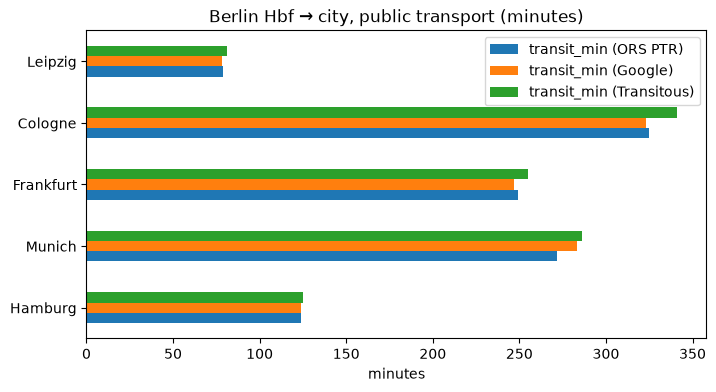

In [ ]:
# Optional: bar chart of transit times
ax = df[[c for c in df.columns if c.startswith('transit_min')]].replace(-9999, None).astype(float) \
       .plot.barh(figsize=(8, 4), title='Berlin Hbf → city, public transport (minutes)')
ax.set_xlabel('minutes');